# Week 7 demos

In [1]:
import gdown
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cmocean as cmo

## Xarray

### Downloading, opening, and inspecting a netCDF file

In [2]:
# Downloading .nc data file from google drive
#gdown.download(id="1jOXqaiSkXoGcB2G0ezHa50nVqeqGE23o", output="data/ofes_ts.nc")

In [3]:
# load the .nc file as an xarray dataset
data_raw = xr.open_dataset('data/ofes_ts.nc')

In [4]:
# inspect the data using display()
display(data_raw)

<xarray.Dataset> Size: 143MB
Dimensions:   (time: 32, lev: 56, lat: 100, lon: 100)
Coordinates:
  * time      (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * lev       (lev) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
  * lat       (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon       (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
Data variables:
    salinity  (time, lev, lat, lon) float32 72MB ...
    temp      (time, lev, lat, lon) float32 72MB ...
Attributes:
    long_name:  [psu] salinity

<!-- BEGIN QUESTION -->

### Poll #1

Based on summary of the dataset displayed above, which of he following is FALSE?

+ The `salinity` values are measured in PSU
+ There are 17920000 values (some may be `NaN`s) in `temp`
+ The span of `lat` is from 4.95°S to 4.95°N
+ The resolution (spacing) of `lev` is 5.0 m


<!-- END QUESTION -->

### Data cleaning and extraction

In [5]:
# rename a dimension
data = data_raw.rename({'lev': 'depth'})
data

<xarray.Dataset> Size: 143MB
Dimensions:   (time: 32, depth: 56, lat: 100, lon: 100)
Coordinates:
  * time      (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * depth     (depth) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
  * lat       (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon       (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
Data variables:
    salinity  (time, depth, lat, lon) float32 72MB ...
    temp      (time, depth, lat, lon) float32 72MB ...
Attributes:
    long_name:  [psu] salinity

In [6]:
# extract a single data variable

salinity = data['salinity']
salinity

<xarray.DataArray 'salinity' (time: 32, depth: 56, lat: 100, lon: 100)> Size: 72MB
[17920000 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * depth    (depth) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon      (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
Attributes:
    long_name:  [psu] salinity

In [7]:
# extract a coordinates
depth = data.coords["depth"]
depth

<xarray.DataArray 'depth' (depth: 56)> Size: 448B
array([  2.5     ,   7.5     ,  12.5     ,  17.5     ,  22.5     ,  27.5     ,
        32.5     ,  37.5     ,  42.5     ,  47.5     ,  52.5     ,  57.5     ,
        62.5     ,  67.5     ,  72.5     ,  77.5     ,  82.5     ,  87.5     ,
        92.5     ,  97.5     , 102.5     , 107.523117, 112.615456, 117.822685,
       123.189758, 128.760666, 134.57811 , 140.683319, 147.115692, 153.912643,
       161.109344, 168.73848 , 176.830093, 185.411346, 194.506424, 204.136292,
       214.318665, 225.067825, 236.394577, 248.306122, 260.806122, 273.894562,
       287.567841, 301.818665, 316.636292, 332.006409, 347.911346, 364.330078,
       381.238464, 398.609344, 416.412628, 434.615692, 453.183319, 472.078125,
       491.260651, 510.689758])
Coordinates:
  * depth    (depth) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
Attributes:
    axis:     Z

In [8]:
# extract the bare numpy arrays
depth_np = depth.values
depth_np

array([  2.5     ,   7.5     ,  12.5     ,  17.5     ,  22.5     ,
        27.5     ,  32.5     ,  37.5     ,  42.5     ,  47.5     ,
        52.5     ,  57.5     ,  62.5     ,  67.5     ,  72.5     ,
        77.5     ,  82.5     ,  87.5     ,  92.5     ,  97.5     ,
       102.5     , 107.523117, 112.615456, 117.822685, 123.189758,
       128.760666, 134.57811 , 140.683319, 147.115692, 153.912643,
       161.109344, 168.73848 , 176.830093, 185.411346, 194.506424,
       204.136292, 214.318665, 225.067825, 236.394577, 248.306122,
       260.806122, 273.894562, 287.567841, 301.818665, 316.636292,
       332.006409, 347.911346, 364.330078, 381.238464, 398.609344,
       416.412628, 434.615692, 453.183319, 472.078125, 491.260651,
       510.689758])

In [9]:
salinity_np = salinity.values
salinity_np.shape

(32, 56, 100, 100)

### Data manipulation

In [10]:
# calculate the density of the seawater using an approximate linear formula
density = (
    1025.27
    + 0.766 * (data["salinity"] - 35.0)
    - 0.247 * (data["temp"] - 18.0)
    + 0.00441 * data.coords["depth"]
)
density

<xarray.DataArray (time: 32, depth: 56, lat: 100, lon: 100)> Size: 143MB
array([[[[1022.14072471, 1022.13681846, 1022.13315635, ...,
          1022.3021627 , 1022.30252891, 1022.30295615],
         [1022.12155967, 1022.11759238, 1022.11393027, ...,
          1022.29923301, 1022.29996543, 1022.30057578],
         [1022.10666709, 1022.10257773, 1022.09891563, ...,
          1022.29654746, 1022.29734092, 1022.29789023],
         ...,
         [1022.23764854, 1022.24820762, 1022.24717002, ...,
          1021.20578818, 1021.21500449, 1021.2242208 ],
         [1022.24112754, 1022.26316123, 1022.28025107, ...,
          1021.21427207, 1021.23563438, 1021.25174766],
         [1022.23331504, 1022.25815635, 1022.28629355, ...,
          1021.22928672, 1021.25455527, 1021.26700645]],

        [[1022.17308965, 1022.16924443, 1022.16558232, ...,
          1022.32457891, 1022.32506719, 1022.32537236],
         [1022.15282598, 1022.1492249 , 1022.145929  , ...,
          1022.32164922, 1022.32238164, 1022.32299199],
         [1022.1368958 , 1022.13347783, 1022.13067021, ...,
          1022.31902471, 1022.31981816, 1022.32048955],
...
          1029.32417431, 1029.32368603, 1029.32270947],
         [1029.31111279, 1029.31392041, 1029.31843701, ...,
          1029.32026806, 1029.31990185, 1029.31880322],
         [1029.31160107, 1029.31416455, 1029.31843701, ...,
          1029.31733838, 1029.31746045, 1029.31660596]],

        [[1029.53290355, 1029.52960765, 1029.52606761, ...,
          1029.47662914, 1029.47577465, 1029.47479808],
         [1029.53729808, 1029.5343684 , 1029.53095043, ...,
          1029.47357738, 1029.47284496, 1029.47199047],
         [1029.53986156, 1029.53766429, 1029.53510082, ...,
          1029.47162425, 1029.47113597, 1029.47040355],
         ...,
         [1029.42535961, 1029.42792308, 1029.43256175, ...,
          1029.44232738, 1029.44122875, 1029.44025218],
         [1029.42511547, 1029.42804515, 1029.4328059 , ...,
          1029.43793285, 1029.43744457, 1029.43671215],
         [1029.42584789, 1029.42841136, 1029.4328059 , ...,
          1029.43451488, 1029.43512523, 1029.43488109]]]],
      shape=(32, 56, 100, 100))
Coordinates:
  * time     (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * depth    (depth) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon      (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
Attributes:
    axis:     Z

<!-- BEGIN QUESTION -->

### Your turn #1

Convert the temperature from celcius to ferenheit, and assign the result to a new data variable called `temp_F`

In [11]:
# Your code here
temp_F = data["temp"] * (9/5) + 32
temp_F.attrs["long_name"] = "[deg F] potential temperature"
display(temp_F)

<xarray.DataArray 'temp' (time: 32, depth: 56, lat: 100, lon: 100)> Size: 72MB
array([[[[84.27372 , 84.26746 , 84.25935 , ..., 83.5047  , 83.49477 ,
          83.48484 ],
         [84.3251  , 84.31851 , 84.3107  , ..., 83.52156 , 83.51175 ,
          83.50127 ],
         [84.362625, 84.35758 , 84.3506  , ..., 83.537415, 83.52903 ,
          83.51967 ],
         ...,
         [84.648994, 84.785645, 85.01277 , ..., 85.02608 , 85.06955 ,
          85.05483 ],
         [84.548935, 84.60565 , 84.73616 , ..., 85.093544, 85.1212  ,
          85.09947 ],
         [84.62483 , 84.61721 , 84.676895, ..., 85.16795 , 85.181435,
          85.16649 ]],

        [[84.20992 , 84.21068 , 84.20946 , ..., 83.50119 , 83.49117 ,
          83.48122 ],
         [84.27153 , 84.27089 , 84.269196, ..., 83.51799 , 83.5081  ,
          83.49759 ],
         [84.318146, 84.31811 , 84.31656 , ..., 83.53375 , 83.5253  ,
          83.5159  ],
...
         [50.516434, 50.496292, 50.45758 , ..., 50.50186 , 50.501537,
          50.506664],
         [50.518288, 50.494137, 50.456394, ..., 50.53456 , 50.532627,
          50.540115],
         [50.51283 , 50.49156 , 50.458347, ..., 50.56256 , 50.55621 ,
          50.561745]],

        [[48.935722, 48.942497, 48.96305 , ..., 49.4832  , 49.497288,
          49.51114 ],
         [48.886063, 48.896156, 48.920258, ..., 49.495914, 49.50654 ,
          49.51875 ],
         [48.85302 , 48.86142 , 48.88186 , ..., 49.50345 , 49.509987,
          49.52105 ],
         ...,
         [50.26957 , 50.246494, 50.206867, ..., 50.266354, 50.26872 ,
          50.271194],
         [50.27193 , 50.24581 , 50.206955, ..., 50.299538, 50.29631 ,
          50.29812 ],
         [50.2675  , 50.24535 , 50.21106 , ..., 50.327362, 50.317   ,
          50.31559 ]]]], shape=(32, 56, 100, 100), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * depth    (depth) float64 448B 2.5 7.5 12.5 17.5 ... 453.2 472.1 491.3 510.7
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon      (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
Attributes:
    long_name:  [deg F] potential temperature

<!-- END QUESTION -->

### Data selection and reduction

In [12]:
# select salinity at sea level, and average over time
# Result is a 2-axes DataArray

sal_mean_surf = salinity.mean('time').isel(depth = 0)
display(sal_mean_surf)

<xarray.DataArray 'salinity' (lat: 100, lon: 100)> Size: 40kB
array([[34.482494, 34.48357 , 34.485016, ..., 34.48666 , 34.48446 ,
        34.481018],
       [34.469864, 34.469738, 34.469612, ..., 34.485764, 34.48349 ,
        34.47985 ],
       [34.455963, 34.454224, 34.452393, ..., 34.484413, 34.48211 ,
        34.47839 ],
       ...,
       [34.43742 , 34.407112, 34.39961 , ..., 33.35626 , 33.359035,
        33.360966],
       [34.426876, 34.38795 , 34.36829 , ..., 33.34619 , 33.348957,
        33.349766],
       [34.422768, 34.386093, 34.363205, ..., 33.338646, 33.340122,
        33.341434]], shape=(100, 100), dtype=float32)
Coordinates:
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon      (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
    depth    float64 8B 2.5
Attributes:
    long_name:  [psu] salinity

<!-- BEGIN QUESTION -->

### Poll #2

Let's say I am interested in the longitude averaged temperature at a depth of (approximately) 10 m. Which of the following will produce the correct DataArray?

+ `data.isel(depth=10).mean("lon")`
+ `data["temp"].isel(depth=10).mean("lon")`
+ `data["temp"].sel(depth=10).mean("lon")`
+ `data["temp"].sel(depth=10, method="nearest").mean("lon")`

In [13]:
data["temp"].sel(depth=10, method="nearest").mean("lon")

<xarray.DataArray 'temp' (time: 32, lat: 100)> Size: 13kB
array([[28.752449, 28.775454, 28.794506, ..., 29.590666, 29.581919,
        29.573309],
       [28.768766, 28.78969 , 28.806913, ..., 29.587097, 29.58251 ,
        29.572325],
       [28.778053, 28.796938, 28.812336, ..., 29.59348 , 29.589676,
        29.587288],
       ...,
       [29.11114 , 29.141436, 29.174263, ..., 29.231823, 29.227337,
        29.223927],
       [29.171192, 29.204092, 29.232512, ..., 29.249567, 29.235683,
        29.229507],
       [29.210142, 29.246258, 29.275564, ..., 29.287975, 29.270035,
        29.25177 ]], shape=(32, 100), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 256B 2019-11-30 2019-12-01 ... 2019-12-31
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
    depth    float64 8B 12.5
Attributes:
    long_name:  [deg C] potential temperature

<!-- END QUESTION -->

## Reshaping multi-dimensional array redux

In [14]:
file_url = 'https://raw.githubusercontent.com/OCEAN-215-2026/week_07_demos/refs/heads/main/data/temperature_grid.csv'
#urlretrieve(file_url, "data/temperature_grid.csv")

In [15]:
temp_df = pd.read_csv("data/temperature_grid.csv")
display(temp_df)

,time,latitude,longitude,temp_C
0,3.0,17.0,63.0,20.0
1,3.0,17.0,64.0,21.5
2,3.0,17.0,65.0,22.0
3,3.0,17.0,66.0,19.5
4,3.0,17.0,67.0,20.0
5,3.0,18.0,63.0,18.0
6,3.0,18.0,64.0,17.5
7,3.0,18.0,65.0,19.0
8,3.0,18.0,66.0,20.0
9,3.0,18.0,67.0,20.5


In [16]:
temp_df = temp_df.set_index(["time", "latitude", "longitude"])
display(temp_df)

temp_C
time latitude longitude        
3.0  17.0     63.0         20.0
              64.0         21.5
              65.0         22.0
              66.0         19.5
              67.0         20.0
     18.0     63.0         18.0
              64.0         17.5
              65.0         19.0
              66.0         20.0
              67.0         20.5
6.0  17.0     63.0         20.5
              64.0         21.0
              65.0         19.5
              66.0         23.0
              67.0         25.1
     18.0     63.0         19.0
              64.0         19.0
              65.0         20.5
              66.0         18.5
              67.0         18.0
9.0  17.0     63.0         23.5
              64.0         24.0
              65.0         22.0
              66.0         22.0
              67.0         25.0
     18.0     63.0         23.0
              64.0         25.0
              65.0         24.0
              66.0         22.5
              67.0         21.5

In [17]:
temp_xr = xr.Dataset.from_dataframe(temp_df)
display(temp_xr)

<xarray.Dataset> Size: 320B
Dimensions:    (time: 3, latitude: 2, longitude: 5)
Coordinates:
  * time       (time) float64 24B 3.0 6.0 9.0
  * latitude   (latitude) float64 16B 17.0 18.0
  * longitude  (longitude) float64 40B 63.0 64.0 65.0 66.0 67.0
Data variables:
    temp_C     (time, latitude, longitude) float64 240B 20.0 21.5 ... 22.5 21.5

In [18]:
temp_xr["temp_C"].values

array([[[20. , 21.5, 22. , 19.5, 20. ],
        [18. , 17.5, 19. , 20. , 20.5]],

       [[20.5, 21. , 19.5, 23. , 25.1],
        [19. , 19. , 20.5, 18.5, 18. ]],

       [[23.5, 24. , 22. , 22. , 25. ],
        [23. , 25. , 24. , 22.5, 21.5]]])

In [19]:
temp_xr.coords["time"].values

array([3., 6., 9.])

In [20]:
temp_xr.coords["latitude"].values

array([17., 18.])

In [21]:
temp_xr.coords["longitude"].values

array([63., 64., 65., 66., 67.])

In [22]:
temp_xr.mean(["time", "longitude"])

<xarray.Dataset> Size: 32B
Dimensions:   (latitude: 2)
Coordinates:
  * latitude  (latitude) float64 16B 17.0 18.0
Data variables:
    temp_C    (latitude) float64 16B 21.91 20.4

## Plotting 2D gridded data

In [23]:
# Example: plotting the time-averaged sea-surface salinity as function of lat and lon

sal_mean_surf = salinity.mean('time').isel(depth = 0)
display(sal_mean_surf)

<xarray.DataArray 'salinity' (lat: 100, lon: 100)> Size: 40kB
array([[34.482494, 34.48357 , 34.485016, ..., 34.48666 , 34.48446 ,
        34.481018],
       [34.469864, 34.469738, 34.469612, ..., 34.485764, 34.48349 ,
        34.47985 ],
       [34.455963, 34.454224, 34.452393, ..., 34.484413, 34.48211 ,
        34.47839 ],
       ...,
       [34.43742 , 34.407112, 34.39961 , ..., 33.35626 , 33.359035,
        33.360966],
       [34.426876, 34.38795 , 34.36829 , ..., 33.34619 , 33.348957,
        33.349766],
       [34.422768, 34.386093, 34.363205, ..., 33.338646, 33.340122,
        33.341434]], shape=(100, 100), dtype=float32)
Coordinates:
  * lat      (lat) float64 800B -4.95 -4.85 -4.75 -4.65 ... 4.65 4.75 4.85 4.95
  * lon      (lon) float64 800B 75.05 75.15 75.25 75.35 ... 84.75 84.85 84.95
    depth    float64 8B 2.5
Attributes:
    long_name:  [psu] salinity

In [24]:
# axis 0 is lat, axis 1 is lon (Good)
sal_array = sal_mean_surf.values

# extract lat and lon array
lat = sal_mean_surf.coords["lat"].values
lon = sal_mean_surf.coords["lon"].values

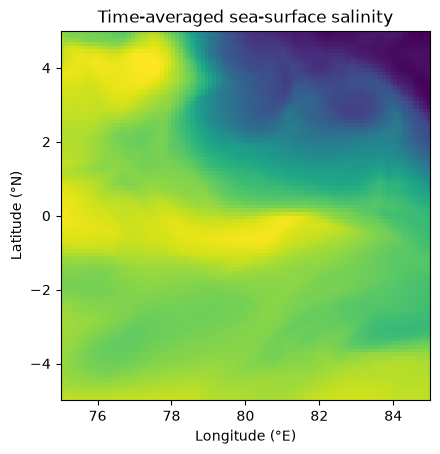

In [25]:
# Now we can do the plotting
# starter code (no color bar)

fig = plt.figure()
ax = fig.add_subplot()

ax.pcolormesh(lon, lat, sal_array)
ax.set_aspect(1)

ax.set_title('Time-averaged sea-surface salinity') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

plt.show(fig)

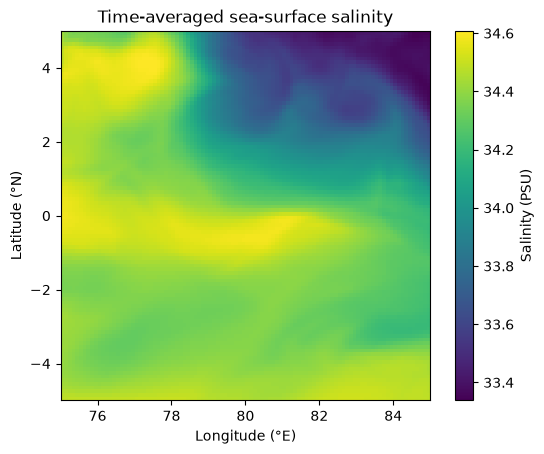

In [26]:
# Including color bar

fig = plt.figure()
ax = fig.add_subplot()

#### NEW
im = ax.pcolormesh(lon, lat, sal_array)

cb = fig.colorbar(im)
cb.set_label("Salinity (PSU)")
#### NEW

ax.set_aspect(1)

ax.set_title('Time-averaged sea-surface salinity') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

plt.show(fig)


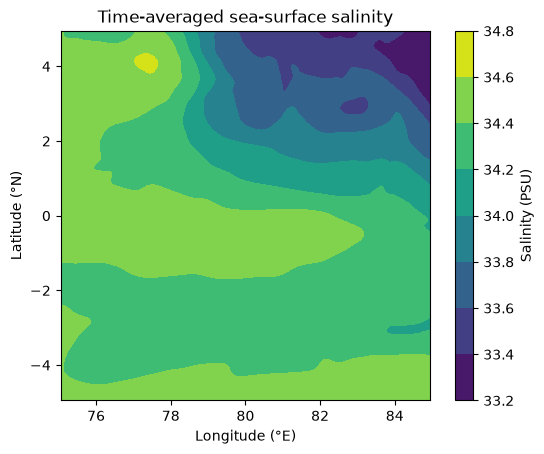

In [27]:
# The same data, but as a filled contour plot

fig = plt.figure()
ax = fig.add_subplot()

#### NEW
im = ax.contourf(lon, lat, sal_array)
#### NEW

cb = fig.colorbar(im)
cb.set_label("Salinity (PSU)")

ax.set_aspect(1)

ax.set_title('Time-averaged sea-surface salinity') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

plt.show(fig)

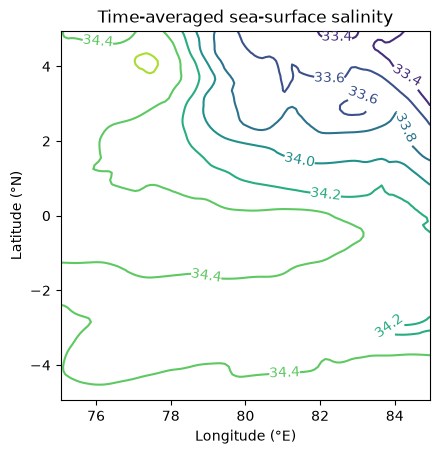

In [28]:
# The same data, but as a line contour plot

fig = plt.figure()
ax = fig.add_subplot()

#### NEW
im = ax.contour(lon, lat, sal_array)

clines = im.clabel()
#### NEW

#cb = fig.colorbar(im)
#cb.set_label("Salinity (PSU)")

ax.set_aspect(1)

ax.set_title('Time-averaged sea-surface salinity') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

plt.show(fig)

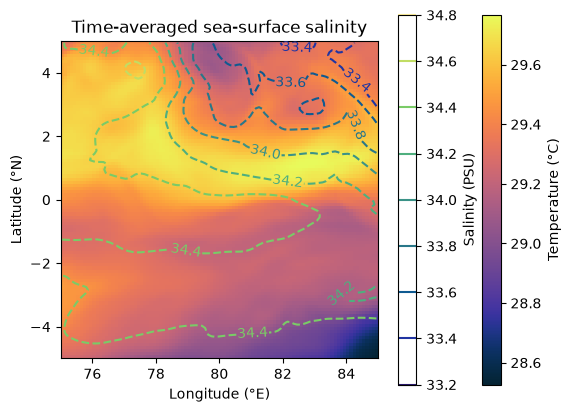

In [29]:
# Overlay salinity line contours on temperature false-color plot

temp_array = data["temp"].mean('time').isel(depth = 0).values

fig = plt.figure()
ax = fig.add_subplot()

im = ax.pcolormesh(lon, lat, temp_array, cmap=cmo.cm.thermal)

cb = plt.colorbar(im)
cb.set_label('Temperature (°C)')

cont = ax.contour(lon, lat, sal_array, cmap=cmo.cm.haline, linestyles="--")
clines = cont.clabel()

cb2 = plt.colorbar(cont)
cb2.set_label('Salinity (PSU)')

ax.set_title('Time-averaged sea-surface salinity') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

ax.set_aspect(1)

plt.show(fig)

<!-- BEGIN QUESTION -->

### Your turn #3

Let's plot the time-average temperature at the equator (0°N) as a function of longitude and depth, using the usual convention that depth increases downwards

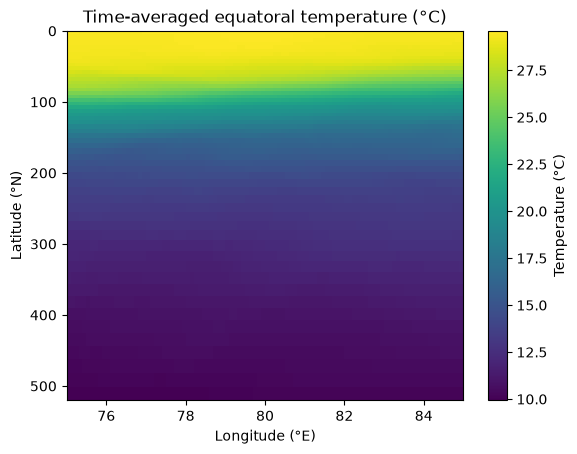

In [30]:
# starter code

temp_eq = data["temp"].sel(lat=0, method="nearest").mean("time")

temp_eq_ar = temp_eq.values
lon = temp_eq.coords["lon"]
depth = temp_eq.coords["depth"]

fig = plt.figure()
ax = fig.add_subplot()

im = ax.pcolormesh(lon, depth, temp_eq_ar)

cb = fig.colorbar(im)
cb.set_label("Temperature (°C)")

ax.invert_yaxis()

ax.set_title('Time-averaged equatoral temperature (°C)') 
ax.set_xlabel('Longitude (°E)') 
ax.set_ylabel('Latitude (°N)')

plt.show(fig)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### Your turn #4

Consider the time-average temperature at the equator (0°N) as before. But this time let's we are interested only in the isotherms (constant temperature lines) from 14°C to 26°C at 2°C intervals. Modify your plot appropriately.

In [31]:
# starter code

temp_eq = data["temp"].sel(lat=0, method="nearest").mean("time")


<!-- END QUESTION -->

